In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
train = pd.read_csv("train.csv")
#test = pd.read_csv("test.csv")
#sample_submission = pd.read_csv("sample_submission.csv")

In [ ]:
data_description = open("data_description.txt")
print(data_description.read())

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [ ]:
display(train.describe()) #zad1
#display(test.describe())
#display(sample_submission.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
display(train.dtypes) #zad2
#display(test.dtypes)
#display(sample_submission.dtypes)

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


Zmienna docelowa: cena domu

Rodzaje zmiennych: dane liczbowe lub kategoryczne

W pierwszej kolejności sprawdzę braki w danych.

In [ ]:
import re

# Read and parse the data description to dynamically extract NA/None reasons
na_reasons = {}
with open("data_description.txt", "r") as f:
    content = f.read()

# Split content by double newlines or sections to find where fields and their sub-values are defined
sections = re.split(r'\n(?=[A-Za-z0-9]+:)', content)
for section in sections:
    lines = [line.strip() for line in section.strip().split('\n') if line.strip()]
    if not lines:
        continue

    # Get field name, e.g., "PoolQC: Pool quality" -> "PoolQC"
    header = lines[0]
    field_match = re.match(r'^([A-Za-z0-9]+):', header)
    if field_match:
        field_name = field_match.group(1)
        # Look for any line starting with "NA" or "None" in this field's description
        na_desc = ""
        for line in lines[1:]:
            if line.startswith("NA") or re.match(r'^NA\s+', line) or line.startswith("None") or re.match(r'^None\s+', line):
                na_desc = re.sub(r'^(NA|None)\s*', '', line).strip()
                break
        if na_desc:
            na_reasons[field_name] = na_desc

# Custom replacements and fallback handler
missing_cols = train.isna().sum()
missing_cols = missing_cols[missing_cols > 0].index.tolist()

for col in missing_cols:
    if col not in na_reasons:
        if col == 'GarageYrBlt':
            na_reasons[col] = 'No Garage'
        else:
            na_reasons[col] = 'Not determined'

naCount = train.isna().sum()
naCount = naCount[naCount > 0].sort_values(ascending=False)
na_df = pd.DataFrame(naCount, columns=['count'])
na_df['naReason'] = na_df.index.map(na_reasons)
display(na_df)

,count,naReason
PoolQC,1453,No Pool
MiscFeature,1406,None
Alley,1369,No alley access
Fence,1179,No Fence
MasVnrType,872,None
FireplaceQu,690,No Fireplace
LotFrontage,259,Not determined
GarageType,81,No Garage
GarageYrBlt,81,No Garage
GarageFinish,81,No Garage


In [ ]:
display(train[train['BsmtQual'].notna() & (train['BsmtExposure'].isna() | train['BsmtFinType2'].isna())]
        [['Id', 'BsmtQual', 'TotalBsmtSF', 'BsmtExposure', 'BsmtFinType2']])

,Id,BsmtQual,TotalBsmtSF,BsmtExposure,BsmtFinType2
332,333,Gd,3206,No,NaN
948,949,Gd,936,NaN,Unf


W danych znalazłem 2 lokale z piwnicą, które mają po 1 wartości `NaN`. Widać, że to braki danych i oba mają piwnicę.

In [ ]:
zeros_count = (train['LotFrontage'] == 0).sum()

print("Zeros Count:", zeros_count)
print("LotFrontage Missing Values:", train['LotFrontage'].isna().sum())
print("Percentage Missing:", train['LotFrontage'].isna().mean() * 100)

config_summary = train.groupby('LotConfig')['LotFrontage'].agg(
    Total_Properties='size',
    Missing_Count=lambda x: x.isna().sum(),
    Pct_Missing=lambda x: x.isna().mean() * 100
).reset_index()

display(config_summary)

Zeros Count: 0
LotFrontage Missing Values: 259
Percentage Missing: 17.73972602739726


,LotConfig,Total_Properties,Missing_Count,Pct_Missing
0,Corner,263,62,23.574144
1,CulDSac,94,49,52.127660
2,FR2,47,14,29.787234
3,FR3,4,0,0.000000
4,Inside,1052,134,12.737643


In [ ]:
masvnr_summary = train.groupby('MasVnrType', dropna=False)['MasVnrArea'].agg(
    Total_Properties='size',
    Missing_Area_Count=lambda x: x.isna().sum(),
    Min_Area='min',
    Median_Area='median',
    Mean_Area='mean',
    Max_Area='max'
).reset_index()

display(masvnr_summary)

,MasVnrType,Total_Properties,Missing_Area_Count,Min_Area,Median_Area,Mean_Area,Max_Area
0,BrkCmn,15,0,41.0,192.0,247.666667,621.0
1,BrkFace,445,0,0.0,202.0,259.008989,1600.0
2,Stone,128,0,0.0,206.5,239.304688,860.0
3,NaN,872,8,0.0,0.0,1.094907,344.0


In [ ]:
train['MasVnrArea'] = train['MasVnrArea'].fillna(0)

remaining_nas = train['MasVnrArea'].isna().sum()
print(f"Remaining NA values in MasVnrArea: {remaining_nas}")

Remaining NA values in MasVnrArea: 0


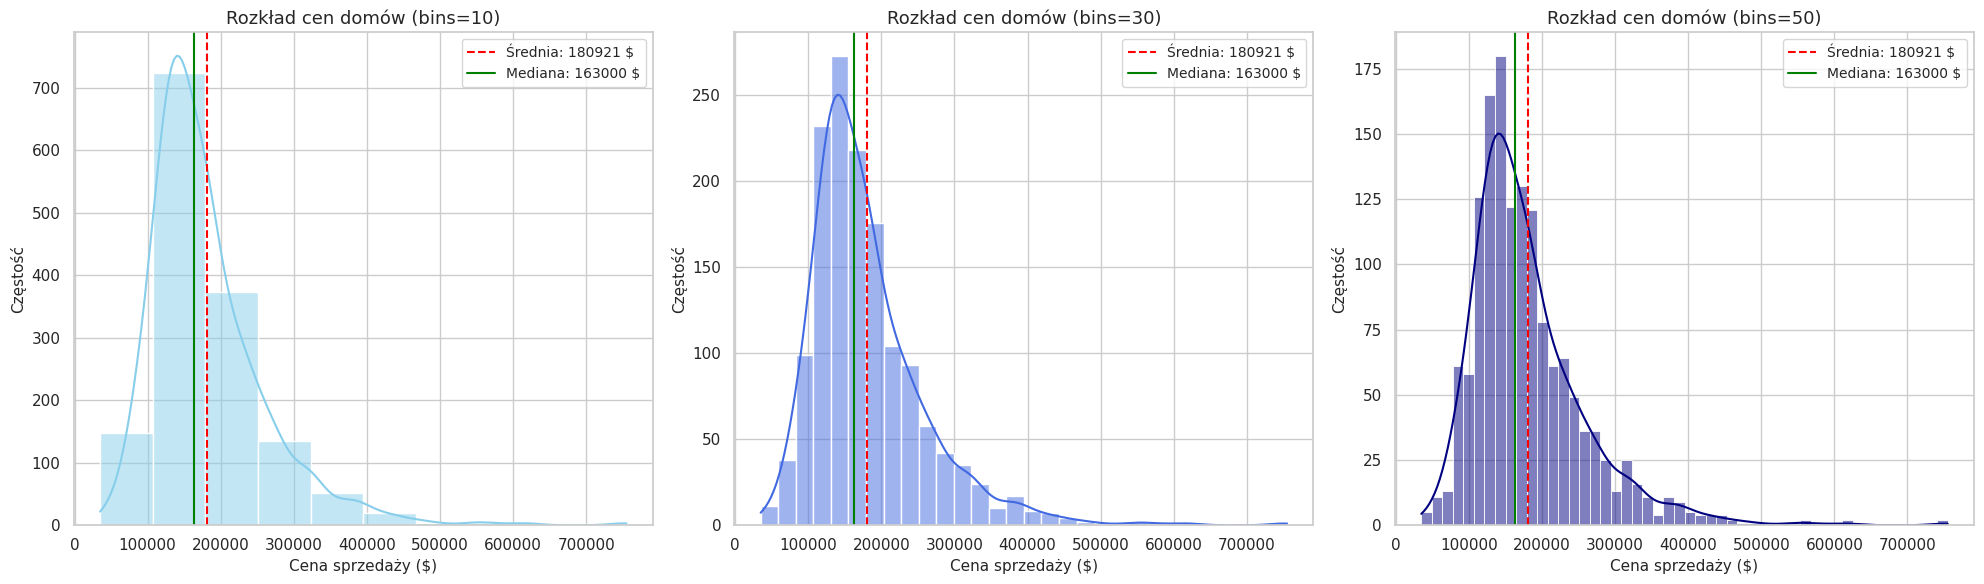

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

bins_values = [10, 30, 50]
colors = ['skyblue', 'royalblue', 'navy']

for i, bins in enumerate(bins_values):
    sns.histplot(ax=axes[i], data=train, x='SalePrice', kde=True, bins=bins, color=colors[i])
    axes[i].set_title(f'Rozkład cen domów (bins={bins})', fontsize=13)
    axes[i].set_xlabel('Cena sprzedaży ($)', fontsize=11)
    axes[i].set_ylabel('Częstość', fontsize=11)

    axes[i].axvline(train['SalePrice'].mean(), color='red', linestyle='--', label=f"Średnia: {train['SalePrice'].mean():.0f} $")
    axes[i].axvline(train['SalePrice'].median(), color='green', linestyle='-', label=f"Mediana: {train['SalePrice'].median():.0f} $")
    axes[i].legend(fontsize=10)

plt.tight_layout()
plt.show()

### Odpowiedzi na pytania
1. Rozkład cen przedstawiony jest na powyższych histogramach. Jak widać jest prawoskośny.
2. Jak widać na wykresie poniżej, są wartości odstające. Prawdopodbnie na cenę wpływa inny czynnik niż jakość, np. powierzchnia.
3. Średnia cena domu: \$180921.20, mediana ceny domu: $163000
4. Nie jest to rozkład normalny, jest prawoskośny.

,OverallQual,Min,Max,Srednia,Mediana,Q1,Q3,IQR
0,1,39300,61000,50150.00,50150.0,44725.0,55575.0,10850.0
1,2,35311,60000,51770.33,60000.0,47655.5,60000.0,12344.5
2,3,37900,139600,87473.75,86250.0,75500.0,97500.0,22000.0
3,4,34900,256000,108420.66,108000.0,88000.0,125500.0,37500.0
4,5,55993,228950,133523.35,133000.0,118000.0,147000.0,29000.0
5,6,76000,277000,161603.03,160000.0,139125.0,181000.0,41875.0
6,7,82500,383970,207716.42,200141.0,179470.0,230750.0,51280.0
7,8,122000,538000,274735.54,269750.0,234557.5,306250.0,71692.5
8,9,239000,611657,367513.02,345000.0,318980.5,389716.0,70735.5
9,10,160000,755000,438588.39,432390.0,349375.0,472875.0,123500.0


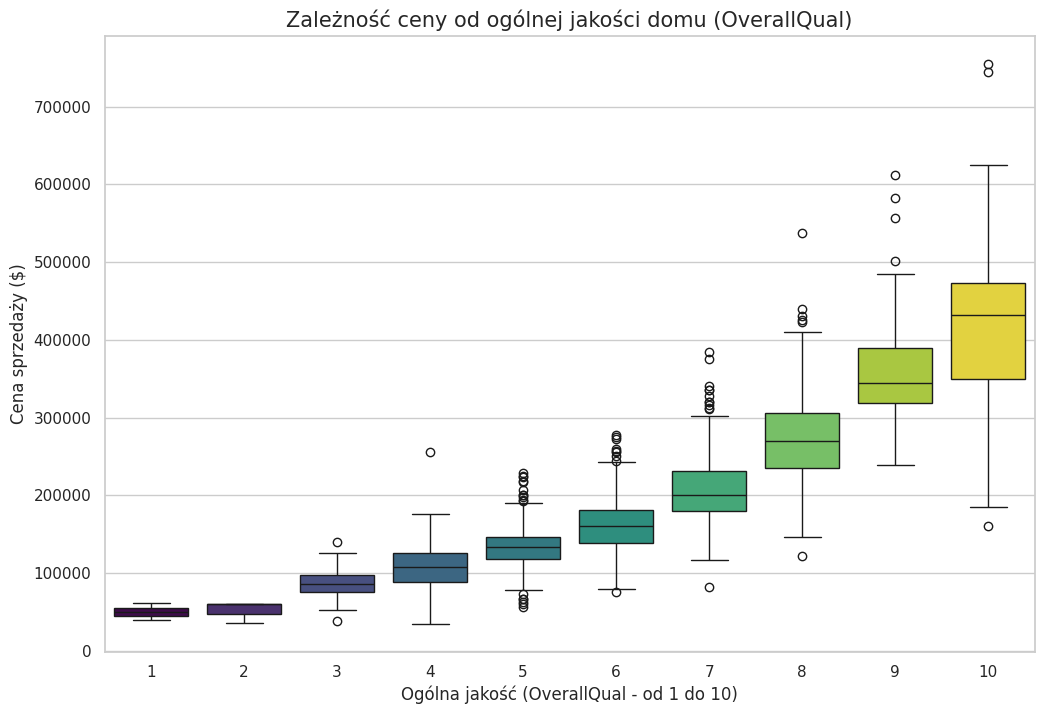

In [ ]:
stats_df = train.groupby('OverallQual')['SalePrice'].agg(
    Min='min',
    Max='max',
    Srednia='mean',
    Mediana='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).reset_index()

stats_df['IQR'] = stats_df['Q3'] - stats_df['Q1']

display(stats_df.round(2))

plt.figure(figsize=(12, 8))
sns.boxplot(x='OverallQual', y='SalePrice', data=train, palette='viridis', hue='OverallQual', legend=False)

plt.title('Zależność ceny od ogólnej jakości domu (OverallQual)', fontsize=15)
plt.xlabel('Ogólna jakość (OverallQual - od 1 do 10)', fontsize=12)
plt.ylabel('Cena sprzedaży ($)', fontsize=12)

plt.show()

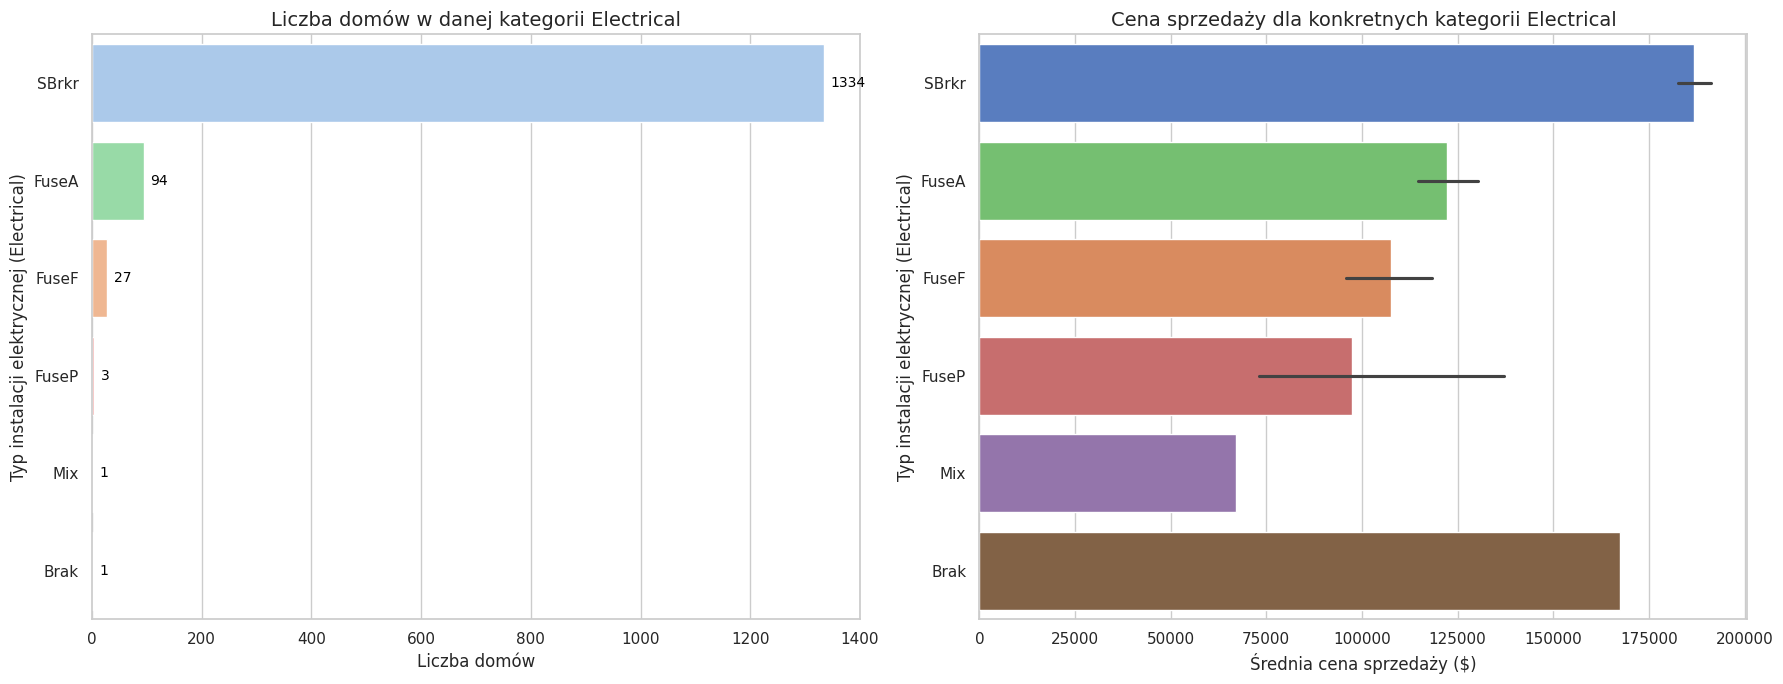

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

electrical_clean = train['Electrical'].fillna('Brak')
order_categories = electrical_clean.value_counts().index

sns.countplot(ax=axes[0], y=electrical_clean, order=order_categories, palette='pastel', hue=electrical_clean, legend=False)
axes[0].set_title('Liczba domów w danej kategorii Electrical', fontsize=14)
axes[0].set_xlabel('Liczba domów', fontsize=12)
axes[0].set_ylabel('Typ instalacji elektrycznej (Electrical)', fontsize=12)

for p in axes[0].patches:
    width = p.get_width() if not np.isnan(p.get_width()) else 0
    axes[0].annotate(f'{int(width)}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=10, color='black', xytext=(5, 0),
                    textcoords='offset points')

sns.barplot(ax=axes[1], x='SalePrice', y=electrical_clean, data=train, order=order_categories, palette='muted', hue=electrical_clean, legend=False)
axes[1].set_title('Cena sprzedaży dla konkretnych kategorii Electrical', fontsize=14)
axes[1].set_xlabel('Średnia cena sprzedaży ($)', fontsize=12)
axes[1].set_ylabel('Typ instalacji elektrycznej (Electrical)', fontsize=12)

plt.tight_layout()
plt.show()

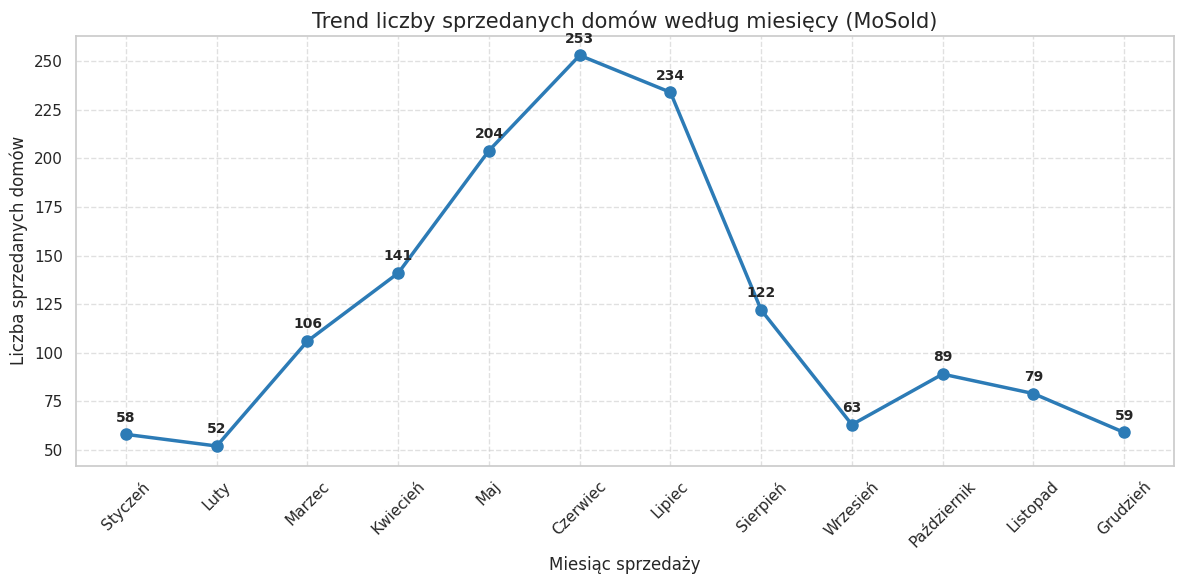

In [ ]:
plt.figure(figsize=(12, 6))

monthly_counts = train['MoSold'].value_counts().sort_index()

miesiace = ['Styczeń', 'Luty', 'Marzec', 'Kwiecień', 'Maj', 'Czerwiec',
            'Lipiec', 'Sierpień', 'Wrzesień', 'Październik', 'Listopad', 'Grudzień']

plt.plot(monthly_counts.index, monthly_counts.values, marker='o', linestyle='-', color='#2c7bb6', linewidth=2.5, markersize=8)

plt.title('Trend liczby sprzedanych domów według miesięcy (MoSold)', fontsize=15)
plt.xlabel('Miesiąc sprzedaży', fontsize=12)
plt.ylabel('Liczba sprzedanych domów', fontsize=12)
plt.xticks(ticks=range(1, 13), labels=miesiace, rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

for x, y in zip(monthly_counts.index, monthly_counts.values):
    plt.text(x, y + 5, str(y), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

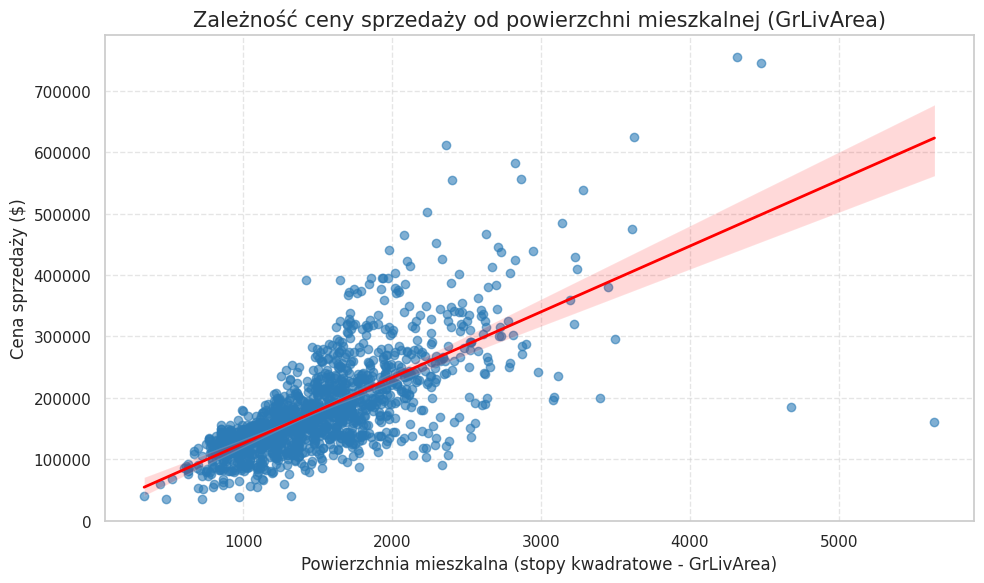

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(data=train, x='GrLivArea', y='SalePrice',
            scatter_kws={'alpha': 0.6, 'color': '#2c7bb6'},
            line_kws={'color': 'red', 'linewidth': 2})

plt.title('Zależność ceny sprzedaży od powierzchni mieszkalnej (GrLivArea)', fontsize=15)
plt.xlabel('Powierzchnia mieszkalna (stopy kwadratowe - GrLivArea)', fontsize=12)
plt.ylabel('Cena sprzedaży ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Na podstawie powyższego wykresu możemy potwierdzić hipotezę, że większe domy są droższe. Można zaobserwować wartości odstające oraz rosnącą wariancję, ale jest to zależność liniowa, co zresztą widać po linii trendu.

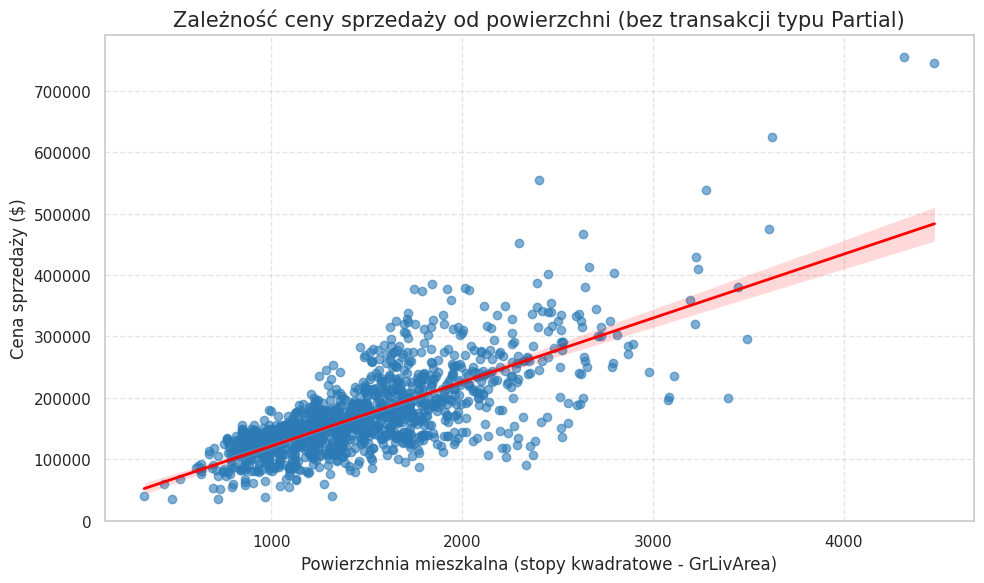

In [ ]:
train_filtered = train[train['SaleCondition'] != 'Partial']

plt.figure(figsize=(10, 6))
sns.regplot(data=train_filtered, x='GrLivArea', y='SalePrice',
            scatter_kws={'alpha': 0.6, 'color': '#2c7bb6'},
            line_kws={'color': 'red', 'linewidth': 2})

plt.title('Zależność ceny sprzedaży od powierzchni (bez transakcji typu Partial)', fontsize=15)
plt.xlabel('Powierzchnia mieszkalna (stopy kwadratowe - GrLivArea)', fontsize=12)
plt.ylabel('Cena sprzedaży ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Po usunięciu transakcji `Partial` znikają dwa nietypowe punkty: największe domy sprzedane poniżej 200 tys. $. Pozostałe duże domy są drogie i pasują do trendu.

Zmienne związane z powierzchnią: ['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']


,Korelacja z SalePrice
GrLivArea,0.709
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
MasVnrArea,0.473
BsmtFinSF1,0.386
WoodDeckSF,0.324
2ndFlrSF,0.319
OpenPorchSF,0.316
LotArea,0.264


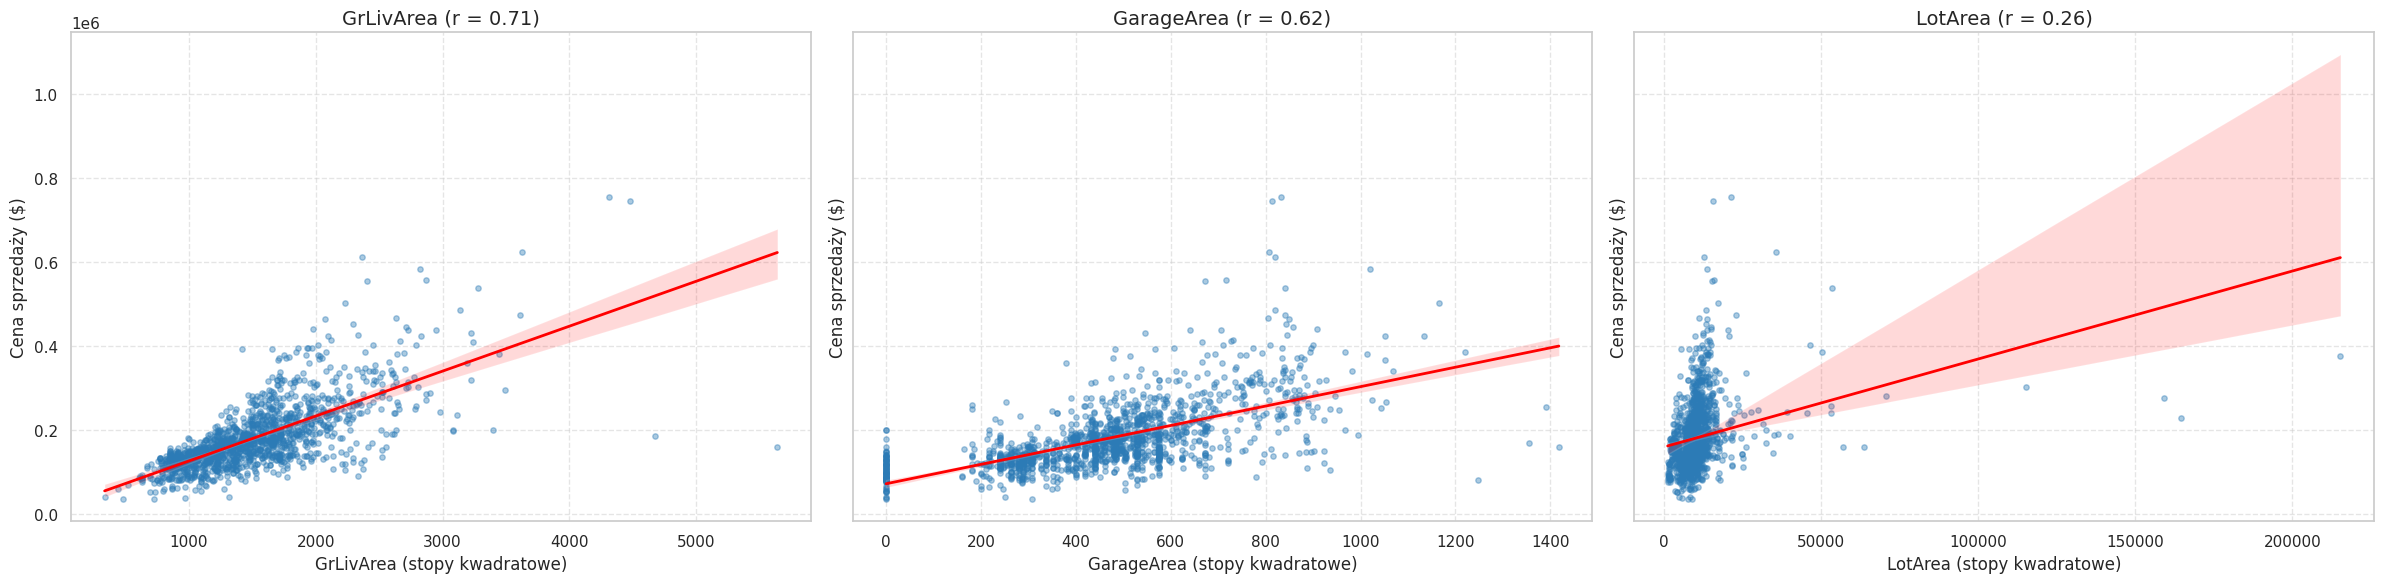

In [ ]:
area_cols = [c for c in train.columns if 'Area' in c or 'SF' in c]
print("Zmienne związane z powierzchnią:", area_cols)

corr = train[area_cols + ['SalePrice']].corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)
display(corr.round(3).to_frame('Korelacja z SalePrice'))

wybrane = ['GrLivArea', 'GarageArea', 'LotArea']
fig, axes = plt.subplots(1, 3, figsize=(24, 6), sharey=True)

for ax, col in zip(axes, wybrane):
    sns.regplot(ax=ax, data=train, x=col, y='SalePrice',
                scatter_kws={'alpha': 0.4, 'color': '#2c7bb6', 's': 15},
                line_kws={'color': 'red', 'linewidth': 2})
    ax.set_title(f'{col} (r = {corr[col]:.2f})', fontsize=14)
    ax.set_xlabel(f'{col} (stopy kwadratowe)', fontsize=12)
    ax.set_ylabel('Cena sprzedaży ($)', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Z analizy wynika, że powierzchnia działki `LotArea` ma stosunkowo małą korelację z wyceną domu w porównaniu do wielu innych zmiennych jak powierzchnia domu `GrLivArea` czy powierzchnia garażu `GarageArea`.